
# 02 — Monetary Policy & Labor Market Analysis

## Project: Macroeconomic Regimes & Portfolio Performance

### Research Objective

Investigate the relationship between US monetary policy,
unemployment, and macroeconomic conditions during 2008–2025.

### Economic Variables

1. **Federal Funds Rate (FEDFUNDS)**
   - Monthly effective federal funds rate (%)
   - Indicator of monetary policy conditions

2. **Unemployment Rate (UNRATE)**
   - Monthly unemployment rate (%)
   - Indicator of labor market conditions

3. **Inflation Rate (CPI YoY)**
   - Annual percentage change in consumer prices
   - Calculated in Notebook 01

### Research Questions

- How have interest rates and unemployment evolved over time?
- How do interest rate changes relate to inflation?
- What statistical relationships exist between inflation,
  unemployment, and monetary policy?

### Methodology

1. Data collection and validation
2. Data cleaning and transformation
3. Exploratory Data Analysis (EDA)
4. Correlation analysis
5. Economic interpretation

**Important:** Correlation does not necessarily imply causation.


In [3]:

import pandas as pd
from pathlib import Path

data_path = Path("../data/raw")

# Load datasets
fed = pd.read_csv(data_path / "FEDFUNDS.csv")
unemployment = pd.read_csv(data_path / "UNRATE.csv")

datasets = {
    "FEDFUNDS": fed,
    "UNRATE": unemployment
}

for name, df in datasets.items():

    print(f"\n--- {name} ---")

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isna().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    display(df.head())
    display(df.tail())



--- FEDFUNDS ---
Shape: (867, 2)
Columns: ['observation_date', 'FEDFUNDS']

Data types:
observation_date     object
FEDFUNDS            float64
dtype: object

Missing values:
observation_date    0
FEDFUNDS            0
dtype: int64

Duplicate rows: 0


,observation_date,FEDFUNDS
0,1954-07-01,0.80
1,1954-08-01,1.22
2,1954-09-01,1.07
3,1954-10-01,0.85
4,1954-11-01,0.83


,observation_date,FEDFUNDS
862,2026-05-01,3.63
863,2026-06-01,3.63
864,2026-07-01,3.63
865,2026-08-01,3.63
866,2026-09-01,3.75



--- UNRATE ---
Shape: (945, 2)
Columns: ['observation_date', 'UNRATE']

Data types:
observation_date     object
UNRATE              float64
dtype: object

Missing values:
observation_date    0
UNRATE              1
dtype: int64

Duplicate rows: 0


,observation_date,UNRATE
0,1948-01-01,3.4
1,1948-02-01,3.8
2,1948-03-01,4.0
3,1948-04-01,3.9
4,1948-05-01,3.5


,observation_date,UNRATE
940,2026-05-01,4.3
941,2026-06-01,4.2
942,2026-07-01,4.1
943,2026-08-01,4.1
944,2026-09-01,4.2


In [4]:

# Convert dates to datetime
fed["observation_date"] = pd.to_datetime(fed["observation_date"])
unemployment["observation_date"] = pd.to_datetime(
    unemployment["observation_date"]
)

# Filter research period (including 2007)
fed_filtered = fed[
    fed["observation_date"].between("2007-01-01", "2025-12-01")
].copy()

unemployment_filtered = unemployment[
    unemployment["observation_date"].between(
        "2007-01-01", "2025-12-01"
    )
].copy()

# Validate filtered datasets
for name, df in {
    "FEDFUNDS": fed_filtered,
    "UNRATE": unemployment_filtered
}.items():

    print(f"\n--- {name} ---")
    print("Shape:", df.shape)
    print("Missing values:", df.isna().sum().to_dict())
    print("Duplicate dates:",
          df["observation_date"].duplicated().sum())

    print("\nMissing observations:")
    display(df[df.isna().any(axis=1)])



--- FEDFUNDS ---
Shape: (228, 2)
Missing values: {'observation_date': 0, 'FEDFUNDS': 0}
Duplicate dates: 0

Missing observations:


,observation_date,FEDFUNDS



--- UNRATE ---
Shape: (228, 2)
Missing values: {'observation_date': 0, 'UNRATE': 1}
Duplicate dates: 0

Missing observations:


,observation_date,UNRATE
933,2025-10-01,NaN


In [5]:

# Sort observations chronologically
fed_filtered = fed_filtered.sort_values(
    "observation_date"
).reset_index(drop=True)

unemployment_filtered = unemployment_filtered.sort_values(
    "observation_date"
).reset_index(drop=True)

# Calculate monthly changes in percentage points
fed_filtered["fed_change_pp"] = fed_filtered["FEDFUNDS"].diff()

unemployment_filtered["unemployment_change_pp"] = (
    unemployment_filtered["UNRATE"].diff()
)

# Inspect the resulting variables
print("FEDFUNDS:")
display(fed_filtered.tail())

print("\nUNEMPLOYMENT:")
display(unemployment_filtered.tail())

print("\nMissing values:")
print("FED:", fed_filtered.isna().sum())
print("UNRATE:", unemployment_filtered.isna().sum())


FEDFUNDS:


,observation_date,FEDFUNDS,fed_change_pp
223,2025-08-01,4.33,0.00
224,2025-09-01,4.22,-0.11
225,2025-10-01,4.09,-0.13
226,2025-11-01,3.88,-0.21
227,2025-12-01,3.72,-0.16



UNEMPLOYMENT:


,observation_date,UNRATE,unemployment_change_pp
223,2025-08-01,4.3,0.0
224,2025-09-01,4.4,0.1
225,2025-10-01,NaN,NaN
226,2025-11-01,4.5,NaN
227,2025-12-01,4.4,-0.1



Missing values:
FED: observation_date    0
FEDFUNDS            0
fed_change_pp       1
dtype: int64
UNRATE: observation_date          0
UNRATE                    1
unemployment_change_pp    3
dtype: int64


In [6]:

# Load the processed inflation dataset from Day 1
inflation = pd.read_csv(
    "../data/processed/us_inflation_2008_2025.csv",
    parse_dates=["observation_date"]
)

# Merge inflation with Federal Funds Rate
macro = inflation.merge(
    fed_filtered,
    on="observation_date",
    how="left",
    validate="one_to_one"
)

# Merge with unemployment data
macro = macro.merge(
    unemployment_filtered,
    on="observation_date",
    how="left",
    validate="one_to_one"
)

# Sort chronologically
macro = macro.sort_values(
    "observation_date"
).reset_index(drop=True)

# Validate the final dataset
print("Final dataset shape:", macro.shape)

print("\nDate range:")
print(macro["observation_date"].min())
print(macro["observation_date"].max())

print("\nMissing values:")
print(macro.isna().sum())

print("\nDuplicate dates:",
      macro["observation_date"].duplicated().sum())

display(macro.head())
display(macro.tail())


Final dataset shape: (216, 7)

Date range:
2008-01-01 00:00:00
2025-12-01 00:00:00

Missing values:
observation_date          0
CPIAUCSL                  1
inflation_yoy             1
FEDFUNDS                  0
fed_change_pp             0
UNRATE                    1
unemployment_change_pp    2
dtype: int64

Duplicate dates: 0


,observation_date,CPIAUCSL,inflation_yoy,FEDFUNDS,fed_change_pp,UNRATE,unemployment_change_pp
0,2008-01-01,212.174,4.294696,3.94,-0.30,5.0,0.0
1,2008-02-01,212.687,4.142959,2.98,-0.96,4.9,-0.1
2,2008-03-01,213.448,3.974904,2.61,-0.37,5.1,0.2
3,2008-04-01,213.942,3.903761,2.28,-0.33,5.0,-0.1
4,2008-05-01,215.208,4.088414,1.98,-0.30,5.4,0.4


,observation_date,CPIAUCSL,inflation_yoy,FEDFUNDS,fed_change_pp,UNRATE,unemployment_change_pp
211,2025-08-01,323.291,2.938592,4.33,0.00,4.3,0.0
212,2025-09-01,324.245,3.022572,4.22,-0.11,4.4,0.1
213,2025-10-01,NaN,NaN,4.09,-0.13,NaN,NaN
214,2025-11-01,325.063,2.696444,3.88,-0.21,4.5,NaN
215,2025-12-01,326.031,2.653304,3.72,-0.16,4.4,-0.1


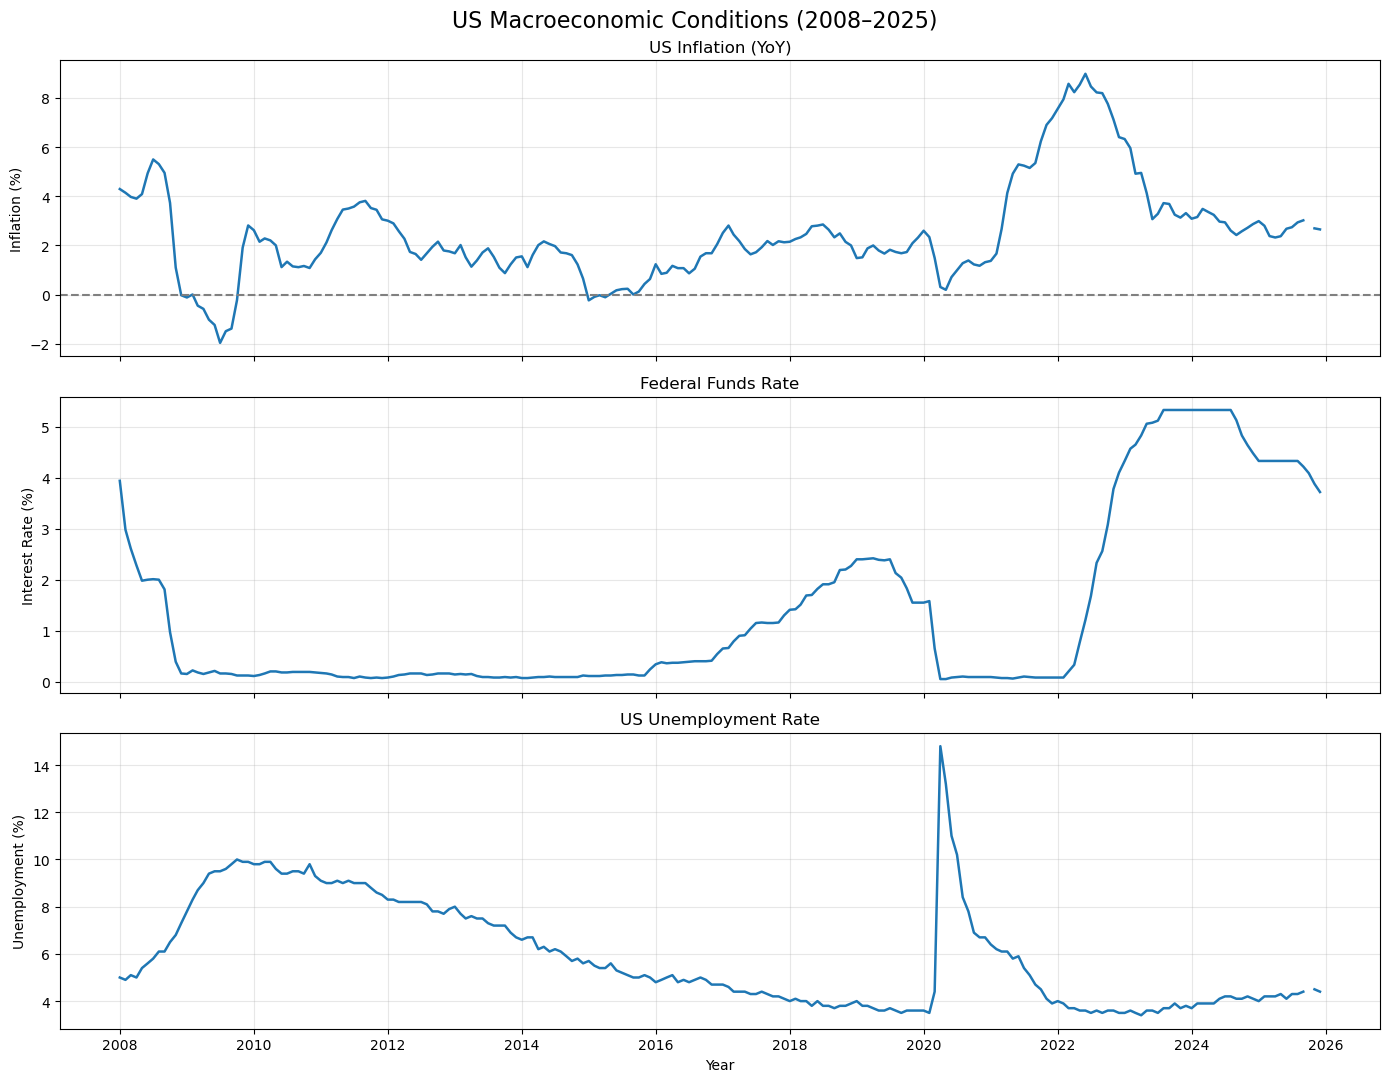

In [7]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 11),
    sharex=True
)

variables = [
    ("inflation_yoy", "US Inflation (YoY)", "Inflation (%)"),
    ("FEDFUNDS", "Federal Funds Rate", "Interest Rate (%)"),
    ("UNRATE", "US Unemployment Rate", "Unemployment (%)")
]

for ax, (column, title, ylabel) in zip(axes, variables):

    ax.plot(
        macro["observation_date"],
        macro[column],
        linewidth=1.8
    )

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)

axes[0].axhline(0, color="gray", linestyle="--")

axes[-1].set_xlabel("Year")

fig.suptitle(
    "US Macroeconomic Conditions (2008–2025)",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [8]:

# Select macroeconomic variables
macro_variables = [
    "inflation_yoy",
    "FEDFUNDS",
    "UNRATE"
]

# Descriptive statistics
descriptive_stats = macro[macro_variables].describe().T

display(descriptive_stats.round(2))

# Pearson correlation matrix
correlation_matrix = macro[macro_variables].corr()

print("\nCorrelation Matrix:")
display(correlation_matrix.round(3))


,count,mean,std,min,25%,50%,75%,max
inflation_yoy,215.0,2.50,2.00,-1.96,1.38,2.15,3.08,8.98
FEDFUNDS,216.0,1.37,1.76,0.05,0.11,0.23,2.19,5.33
UNRATE,215.0,5.91,2.24,3.40,4.00,5.10,7.75,14.80



Correlation Matrix:


,inflation_yoy,FEDFUNDS,UNRATE
inflation_yoy,1.000,0.316,-0.422
FEDFUNDS,0.316,1.000,-0.595
UNRATE,-0.422,-0.595,1.000


In [9]:

# Monthly change in the annual inflation rate
macro["inflation_change_pp"] = macro["inflation_yoy"].diff()

# Correlations between changes
change_variables = [
    "inflation_change_pp",
    "fed_change_pp",
    "unemployment_change_pp"
]

change_corr = macro[change_variables].corr()

print("Correlation Matrix — Monthly Changes")
display(change_corr.round(3))

# Check how many valid observations support each pair
valid = macro[change_variables].notna().astype(int)
pairwise_counts = valid.T @ valid

print("Pairwise observation counts:")
display(pairwise_counts)


Correlation Matrix — Monthly Changes


,inflation_change_pp,fed_change_pp,unemployment_change_pp
inflation_change_pp,1.000,0.188,-0.242
fed_change_pp,0.188,1.000,-0.267
unemployment_change_pp,-0.242,-0.267,1.000


Pairwise observation counts:


,inflation_change_pp,fed_change_pp,unemployment_change_pp
inflation_change_pp,213,213,213
fed_change_pp,213,216,214
unemployment_change_pp,213,214,214


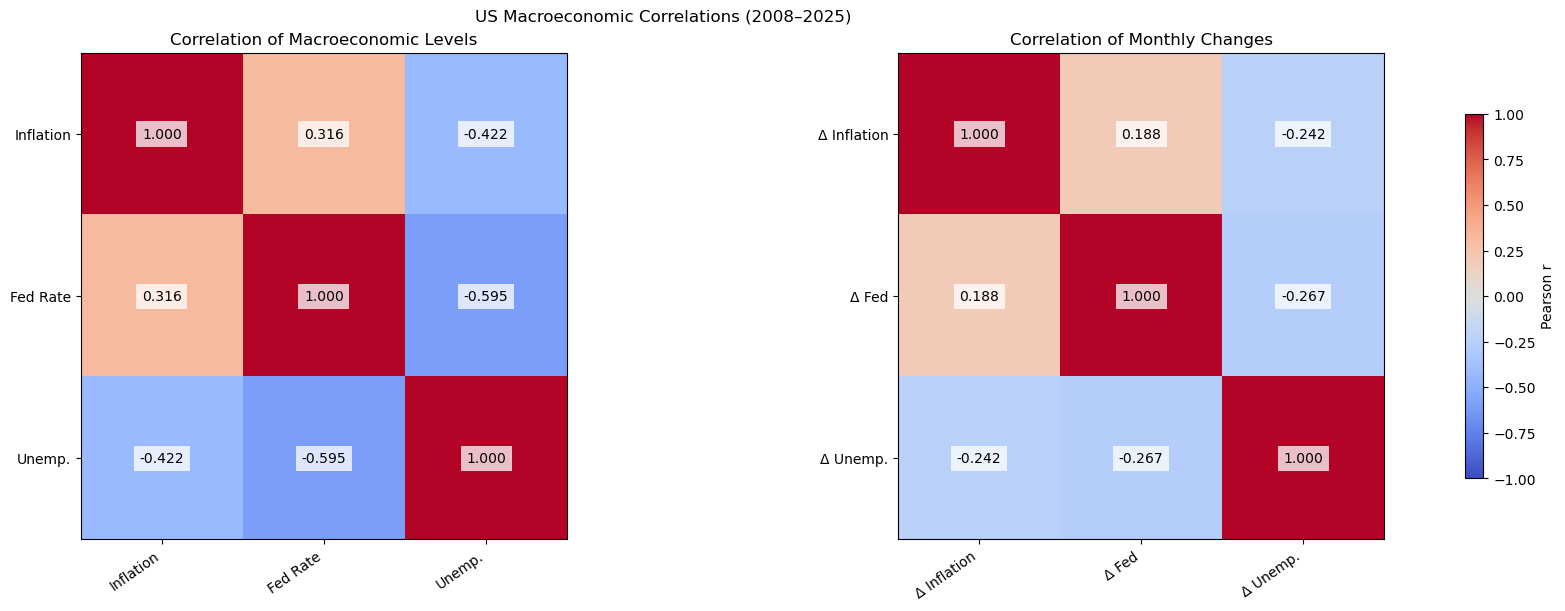

In [12]:

import matplotlib.pyplot as plt
from pathlib import Path

matrices = [
    correlation_matrix,
    change_corr
]

titles = [
    "Correlation of Macroeconomic Levels",
    "Correlation of Monthly Changes"
]

labels = [
    ["Inflation", "Fed Rate", "Unemp."],
    ["Δ Inflation", "Δ Fed", "Δ Unemp."]
]


fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 6),
    layout="constrained"
)

for ax, matrix, title, names in zip(
    axes, matrices, titles, labels
):
    im = ax.imshow(
        matrix.values,
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    ax.set_xticks(range(3), labels=names, rotation=35, ha="right")
    ax.set_yticks(range(3), labels=names)
    ax.set_title(title)

    for i in range(3):
        for j in range(3):
            value = matrix.iloc[i, j]

            ax.text(
                j, i,
                f"{value:.3f}",
                ha="center",
                va="center",
                color="black",
                bbox=dict(
                    facecolor="white",
                    alpha=0.75,
                    edgecolor="none"
                )
            )

fig.colorbar(im, ax=axes, shrink=0.75, label="Pearson r")
fig.suptitle("US Macroeconomic Correlations (2008–2025)")

# Save the figure for the final PowerPoint
output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "macro_correlation_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [13]:

from pathlib import Path

# Define output path
output_path = Path("../data/processed/us_macro_2008_2025.csv")

# Final data validation
assert len(macro) == 216
assert macro["observation_date"].is_unique
assert macro["observation_date"].is_monotonic_increasing

# Save the processed macroeconomic dataset
macro.to_csv(output_path, index=False)

print("Macroeconomic dataset saved successfully!")
print("Location:", output_path.resolve())
print("Shape:", macro.shape)

display(macro.head())


Macroeconomic dataset saved successfully!
Location: C:\Users\ch_mi\PycharmProjects\pythonProject\macroeconomic-regimes-portfolio-analysis\data\processed\us_macro_2008_2025.csv
Shape: (216, 8)


,observation_date,CPIAUCSL,inflation_yoy,FEDFUNDS,fed_change_pp,UNRATE,unemployment_change_pp,inflation_change_pp
0,2008-01-01,212.174,4.294696,3.94,-0.30,5.0,0.0,NaN
1,2008-02-01,212.687,4.142959,2.98,-0.96,4.9,-0.1,-0.151736
2,2008-03-01,213.448,3.974904,2.61,-0.37,5.1,0.2,-0.168056
3,2008-04-01,213.942,3.903761,2.28,-0.33,5.0,-0.1,-0.071143
4,2008-05-01,215.208,4.088414,1.98,-0.30,5.4,0.4,0.184653



## Key Findings — Macroeconomic Analysis

### 1. Macroeconomic Conditions (2008–2025)

Our analysis identifies three major periods of
macroeconomic instability:

- **2008–2009:** Financial crisis, declining interest
  rates, rising unemployment and falling inflation.
- **2020:** COVID-19 shock, characterized by a sharp
  increase in unemployment and monetary easing.
- **2021–2023:** Rapid inflation followed by
  substantial monetary tightening.

### 2. Correlation Analysis

Pearson correlations between macroeconomic levels:

- Inflation and interest rates: +0.316
- Inflation and unemployment: -0.422
- Interest rates and unemployment: -0.595

Correlations between monthly changes:

- Inflation change and interest rate change: +0.188
- Inflation change and unemployment change: -0.242
- Interest rate change and unemployment change: -0.267

### 3. Economic Interpretation

Relationships become weaker when analyzing monthly
changes rather than levels.

This suggests that macroeconomic relationships
depend on variable transformations and time horizons.

The negative relationship between interest rates
and unemployment may partly reflect the Federal
Reserve's response to economic conditions.

### 4. Limitations

- Correlation does not establish causation.
- Monetary policy effects may occur with time lags.
- Macroeconomic variables exhibit temporal dependence.
- Some observations are missing in October 2025.
- Publication delays are not modeled in this
  descriptive analysis.

### 5. Next Steps

- Investigate lagged macroeconomic relationships.
- Integrate financial market data.
- Analyze asset performance under different
  macroeconomic conditions.
